In [ ]:
import os

print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'application_train.csv', 'drive', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/application_train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7760, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Check dataset information
print("Number of rows and columns:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

Number of rows and columns: (7760, 122)

Column names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLU

In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Show columns that have missing values
missing_values = missing_values[missing_values > 0]

print("Columns with missing values:")
print(missing_values.sort_values(ascending=False))

print("\nTotal missing values:", df.isnull().sum().sum())


Columns with missing values:
COMMONAREA_AVG              5409
COMMONAREA_MODE             5409
COMMONAREA_MEDI             5409
NONLIVINGAPARTMENTS_AVG     5385
NONLIVINGAPARTMENTS_MODE    5385
                            ... 
FLAG_DOCUMENT_16               1
FLAG_DOCUMENT_15               1
FLAG_DOCUMENT_14               1
FLAG_DOCUMENT_20               1
FLAG_DOCUMENT_21               1
Length: 112, dtype: int64

Total missing values: 230664


In [ ]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Sort from highest to lowest
missing_percentage = missing_percentage.sort_values(ascending=False)

# Display top 20 columns
print(missing_percentage.head(20))

COMMONAREA_AVG              69.703608
COMMONAREA_MODE             69.703608
COMMONAREA_MEDI             69.703608
NONLIVINGAPARTMENTS_MEDI    69.394330
NONLIVINGAPARTMENTS_MODE    69.394330
NONLIVINGAPARTMENTS_AVG     69.394330
FONDKAPREMONT_MODE          68.505155
LIVINGAPARTMENTS_AVG        68.337629
LIVINGAPARTMENTS_MEDI       68.337629
LIVINGAPARTMENTS_MODE       68.337629
FLOORSMIN_MODE              67.770619
FLOORSMIN_AVG               67.770619
FLOORSMIN_MEDI              67.770619
OWN_CAR_AGE                 66.417526
YEARS_BUILD_MODE            66.340206
YEARS_BUILD_MEDI            66.340206
YEARS_BUILD_AVG             66.340206
LANDAREA_MEDI               59.085052
LANDAREA_AVG                59.085052
LANDAREA_MODE               59.085052
dtype: float64


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Find columns with more than 60% missing values
columns_to_drop = missing_percentage[missing_percentage > 60].index

# Remove those columns
df_clean = df_clean.drop(columns=columns_to_drop)

print("Original dataset shape:", df.shape)
print("After removing columns:", df_clean.shape)
print("Number of columns removed:", len(columns_to_drop))

Original dataset shape: (7760, 122)
After removing columns: (7760, 105)
Number of columns removed: 17


In [ ]:
# Count customers in each category
print(df_clean['TARGET'].value_counts())

# Calculate percentage
print("\nPercentage distribution:")
print(df_clean['TARGET'].value_counts(normalize=True) * 100)

TARGET
0    7162
1     598
Name: count, dtype: int64

Percentage distribution:
TARGET
0    92.293814
1     7.706186
Name: proportion, dtype: float64


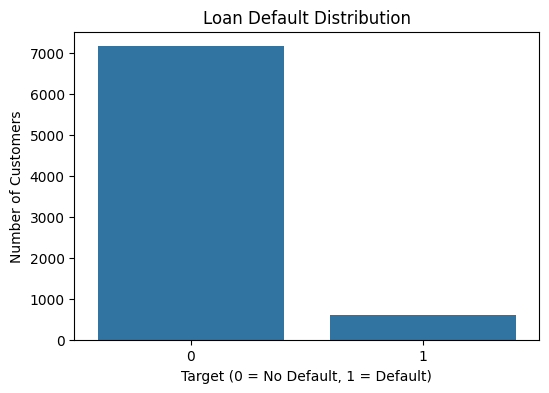

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x='TARGET')

plt.title('Loan Default Distribution')
plt.xlabel('Target (0 = No Default, 1 = Default)')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
# Statistical summary of numerical columns
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,7760.0,104530.748969,2614.054159,100002.0,102273.5,104538.5,106807.25,109052.0
TARGET,7760.0,0.077062,0.266707,0.0,0.0,0.0,0.00,1.0
CNT_CHILDREN,7760.0,0.413273,0.715814,0.0,0.0,0.0,1.00,7.0
AMT_INCOME_TOTAL,7760.0,167245.538422,94925.495642,25650.0,112500.0,144000.0,202500.00,1935000.0
AMT_CREDIT,7760.0,600454.976289,402208.665579,45000.0,270000.0,509602.5,810000.00,2925000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,6714.0,0.008043,0.121786,0.0,0.0,0.0,0.00,4.0
AMT_REQ_CREDIT_BUREAU_WEEK,6714.0,0.033810,0.197302,0.0,0.0,0.0,0.00,4.0
AMT_REQ_CREDIT_BUREAU_MON,6714.0,0.271522,0.928392,0.0,0.0,0.0,0.00,16.0
AMT_REQ_CREDIT_BUREAU_QRT,6714.0,0.268245,0.614135,0.0,0.0,0.0,0.00,8.0


In [ ]:
# Identify categorical columns
categorical_columns = df_clean.select_dtypes(include=['object']).columns

print("Total categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns.tolist())

Total categorical columns: 15

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [ ]:
# Separate numerical and categorical columns
numerical_columns = df_clean.select_dtypes(include=['number']).columns
categorical_columns = df_clean.select_dtypes(include=['object']).columns

# Fill missing numerical values with median
for col in numerical_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with mode
for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Check remaining missing values
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [ ]:
# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(df_clean, drop_first=True, dtype=int)

# Display results
print("Original cleaned dataset:", df_clean.shape)
print("Encoded dataset:", df_encoded.shape)

print("\nFirst 5 rows:")
display(df_encoded.head())

Original cleaned dataset: (7760, 105)
Encoded dataset: (7760, 207)

First 5 rows:


,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,ORGANIZATION_TYPE_XNA,HOUSETYPE_MODE_specific housing,HOUSETYPE_MODE_terraced house,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_Yes
0,100002,1,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461.0,-637.0,...,0,0,0,0,0,0,0,1,0,0
1,100003,0,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765.0,-1188.0,...,0,0,0,0,0,0,0,0,0,0
2,100004,0,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046.0,-225.0,...,0,0,0,0,0,0,1,0,0,0
3,100006,0,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005.0,-3039.0,...,0,0,0,0,0,0,1,0,0,0
4,100007,0,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932.0,-3038.0,...,0,0,0,0,0,0,1,0,0,0


In [ ]:
# Separate input features and target variable
X = df_encoded.drop('TARGET', axis=1)
y = df_encoded['TARGET']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7760, 206)
Target shape: (7760,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (6208, 206)
Testing data: (1552, 206)

Training target distribution:
TARGET
0    5730
1     478
Name: count, dtype: int64

Testing target distribution:
TARGET
0    1432
1     120
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate model
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

Logistic Regression Accuracy: 0.5908505154639175

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.59      0.73      1432
           1       0.11      0.58      0.18       120

    accuracy                           0.59      1552
   macro avg       0.53      0.59      0.45      1552
weighted avg       0.88      0.59      0.69      1552


Confusion Matrix:
[[847 585]
 [ 50  70]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate model
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest Accuracy: 0.8737113402061856

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      1432
           1       0.20      0.22      0.21       120

    accuracy                           0.87      1552
   macro avg       0.57      0.57      0.57      1552
weighted avg       0.88      0.87      0.88      1552


Confusion Matrix:
[[1330  102]
 [  94   26]]


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(X_train, y_train)

# Make predictions
gb_predictions = gb_model.predict(X_test)

# Evaluate model
print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, gb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, gb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_predictions))

Gradient Boosting Accuracy: 0.9201030927835051

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      1432
           1       0.38      0.05      0.09       120

    accuracy                           0.92      1552
   macro avg       0.65      0.52      0.52      1552
weighted avg       0.88      0.92      0.89      1552


Confusion Matrix:
[[1422   10]
 [ 114    6]]


In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Before SMOTE:", Counter(y_train))
print("After SMOTE:", Counter(y_train_smote))

Before SMOTE: Counter({0: 5730, 1: 478})
After SMOTE: Counter({0: 5730, 1: 5730})


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create Random Forest model
rf_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Train using SMOTE data
rf_smote.fit(X_train_smote, y_train_smote)

# Predict using original test data
rf_smote_predictions = rf_smote.predict(X_test)

# Evaluate
print("Random Forest with SMOTE")
print("Accuracy:", accuracy_score(y_test, rf_smote_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_smote_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_smote_predictions))

Random Forest with SMOTE
Accuracy: 0.9188144329896907

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      1432
           1       0.36      0.07      0.11       120

    accuracy                           0.92      1552
   macro avg       0.65      0.53      0.54      1552
weighted avg       0.88      0.92      0.89      1552


Confusion Matrix:
[[1418   14]
 [ 112    8]]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Store predictions from all models
models = {
    "Logistic Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosting": gb_predictions,
    "Random Forest with SMOTE": rf_smote_predictions
}

# Calculate performance metrics
results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

comparison_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(comparison_df.round(3))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.591,0.107,0.583,0.181
1,Random Forest,0.874,0.203,0.217,0.210
2,Gradient Boosting,0.920,0.375,0.050,0.088
3,Random Forest with SMOTE,0.919,0.364,0.067,0.113


Top 15 Important Features:


,Feature,Importance
29,EXT_SOURCE_3,0.065614
18,REGION_RATING_CLIENT,0.046146
15,FLAG_PHONE,0.044700
28,EXT_SOURCE_2,0.041212
104,NAME_EDUCATION_TYPE_Higher education,0.039028
19,REGION_RATING_CLIENT_W_CITY,0.035410
25,REG_CITY_NOT_WORK_CITY,0.034272
27,EXT_SOURCE_1,0.029847
58,OBS_30_CNT_SOCIAL_CIRCLE,0.027469
60,OBS_60_CNT_SOCIAL_CIRCLE,0.025733


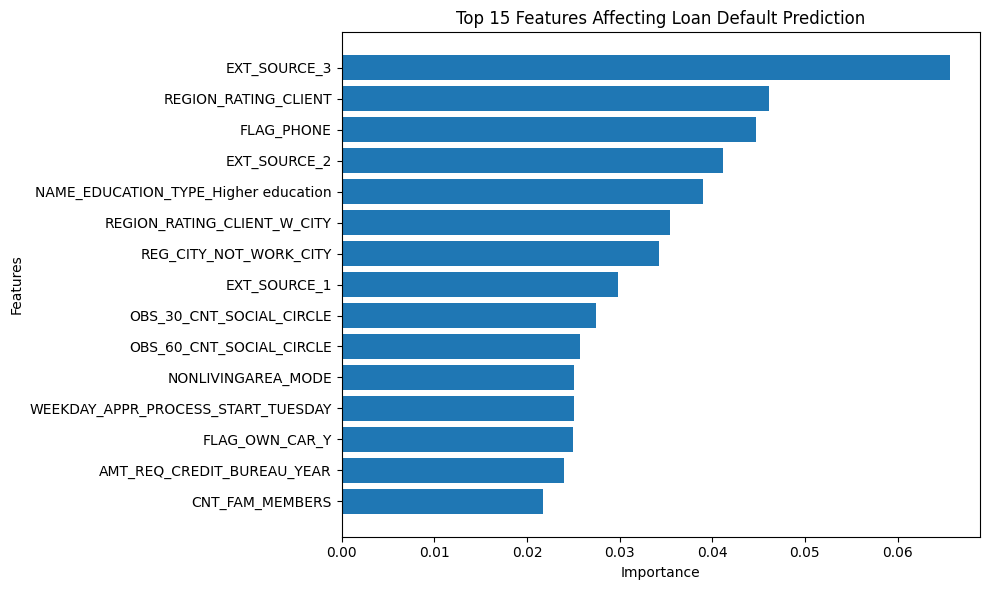

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_smote.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
display(feature_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(15)['Feature'][::-1],
    feature_importance.head(15)['Importance'][::-1]
)

plt.title("Top 15 Features Affecting Loan Default Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Save trained model
joblib.dump(rf_smote, 'home_loan_default_model.pkl')

# Save feature names
joblib.dump(X.columns.tolist(), 'model_features.pkl')

print("Model saved successfully!")
print("Feature names saved successfully!")

Model saved successfully!
Feature names saved successfully!


In [ ]:
from google.colab import files

files.download('home_loan_default_model.pkl')
files.download('model_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download('home_loan_default_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download('home_loan_default_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download('home_loan_default_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

dataset_path = "/content/dataset"

for file in os.listdir(dataset_path):
    print(file)

In [ ]:
import os

dataset_path = "/content/dataset"

for file in os.listdir(dataset_path):
    file_path = os.path.join(dataset_path, file)
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"{file}  —  {size_mb:.2f} MB")

In [ ]:
import os

print("Files available in /content:\n")

for item in os.listdir("/content"):
    print(item)

Files available in /content:

.config
.ipynb_checkpoints
home_loan_default_model.pkl
application_train.csv
model_features.pkl
dataset
drive
sample_data


In [ ]:
import os

dataset_path = "/content/dataset"

print("Dataset folder contents:")

for root, folders, files in os.walk(dataset_path):
    for file in files:
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{file} — {size_mb:.2f} MB")

Dataset folder contents:


In [ ]:
import os

print("Files uploaded in /content:\n")

for file in os.listdir("/content"):
    if file.endswith(".csv") or file.endswith(".zip"):
        size_mb = os.path.getsize("/content/" + file) / (1024 * 1024)
        print(f"{file} — {size_mb:.2f} MB")

Files uploaded in /content:

bureau.csv — 10.00 MB
application_train.csv — 4.00 MB
previous_application.csv — 31.00 MB
installments_payments.csv — 9.00 MB
credit_card_balance.csv — 9.00 MB
POS_CASH_balance.csv — 153.00 MB
bureau_balance.csv — 10.00 MB


In [ ]:
import os

print("ALL CSV FILES FOUND:\n")

csv_files = []

for root, folders, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            csv_files.append(path)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{file}  |  {size_mb:.2f} MB  |  {path}")

print("\nTotal CSV files:", len(csv_files))

ALL CSV FILES FOUND:

bureau.csv  |  10.00 MB  |  /content/bureau.csv
application_train.csv  |  4.00 MB  |  /content/application_train.csv
previous_application.csv  |  44.00 MB  |  /content/previous_application.csv
installments_payments.csv  |  9.00 MB  |  /content/installments_payments.csv
credit_card_balance.csv  |  9.00 MB  |  /content/credit_card_balance.csv
POS_CASH_balance.csv  |  153.00 MB  |  /content/POS_CASH_balance.csv
bureau_balance.csv  |  10.00 MB  |  /content/bureau_balance.csv
mnist_train_small.csv  |  34.83 MB  |  /content/sample_data/mnist_train_small.csv
mnist_test.csv  |  17.44 MB  |  /content/sample_data/mnist_test.csv
california_housing_test.csv  |  0.29 MB  |  /content/sample_data/california_housing_test.csv
california_housing_train.csv  |  1.63 MB  |  /content/sample_data/california_housing_train.csv

Total CSV files: 11


In [ ]:
import pandas as pd
import os

data_path = "/content"

files = [
    "application_train.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "previous_application.csv",
    "installments_payments.csv",
    "credit_card_balance.csv",
    "POS_CASH_balance.csv"
]

for file in files:
    path = os.path.join(data_path, file)

    # Read only column names first
    columns = pd.read_csv(path, nrows=0).columns.tolist()

    # Count rows in chunks to avoid loading large files into memory
    row_count = sum(
        len(chunk)
        for chunk in pd.read_csv(path, usecols=[columns[0]], chunksize=100000)
    )

    print(f"\n{file}")
    print("Rows:", row_count)
    print("Columns:", len(columns))
    print("First 10 columns:", columns[:10])


application_train.csv
Rows: 7760
Columns: 122
First 10 columns: ['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']

bureau.csv
Rows: 106218
Columns: 17
First 10 columns: ['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG']

bureau_balance.csv
Rows: 762556
Columns: 3
First 10 columns: ['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

previous_application.csv
Rows: 318150
Columns: 37
First 10 columns: ['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START']

installments_payments.csv
Rows: 177566
Columns: 8
First 10 columns: ['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'D

In [ ]:
import pandas as pd

file_path = "/content/POS_CASH_balance.csv"

df_pos = pd.read_csv(file_path)

print("POS_CASH_balance dataset")
print("Rows:", df_pos.shape[0])
print("Columns:", df_pos.shape[1])
print("\nColumn names:")
print(df_pos.columns.tolist())

display(df_pos.head())

/tmp/ipykernel_1020/856170964.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pos = pd.read_csv(file_path)


POS_CASH_balance dataset
Rows: 4083156
Columns: 8

Column names:
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0.0,0.0
1,1715348,367990,-33,36.0,35.0,Active,0.0,0.0
2,1784872,397406,-32,12.0,9.0,Active,0.0,0.0
3,1903291,269225,-35,48.0,42.0,Active,0.0,0.0
4,2341044,334279,-35,36.0,35.0,Active,0.0,0.0


In [41]:
import pandas as pd

# Convert numeric columns safely
numeric_cols = [
    "MONTHS_BALANCE",
    "CNT_INSTALMENT",
    "CNT_INSTALMENT_FUTURE",
    "SK_DPD",
    "SK_DPD_DEF"
]

for col in numeric_cols:
    df_pos[col] = pd.to_numeric(df_pos[col], errors="coerce")

# Aggregate customer records
pos_agg = df_pos.groupby("SK_ID_CURR").agg({
    "MONTHS_BALANCE": ["min", "max", "mean"],
    "CNT_INSTALMENT": ["mean", "max"],
    "CNT_INSTALMENT_FUTURE": ["mean", "max"],
    "SK_DPD": ["sum", "max", "mean"],
    "SK_DPD_DEF": ["sum", "max", "mean"]
})

# Rename columns
pos_agg.columns = [
    "POS_" + "_".join(col) for col in pos_agg.columns
]

# Count contract statuses
status_counts = pd.crosstab(
    df_pos["SK_ID_CURR"],
    df_pos["NAME_CONTRACT_STATUS"].astype(str)
)

status_counts.columns = [
    "POS_STATUS_" + str(col).replace(" ", "_")
    for col in status_counts.columns
]

# Combine results
pos_agg = pos_agg.join(status_counts)

print("POS aggregation completed successfully!")
print("Shape:", pos_agg.shape)

display(pos_agg.head())

POS aggregation completed successfully!
Shape: (317901, 22)


,POS_MONTHS_BALANCE_min,POS_MONTHS_BALANCE_max,POS_MONTHS_BALANCE_mean,POS_CNT_INSTALMENT_mean,POS_CNT_INSTALMENT_max,POS_CNT_INSTALMENT_FUTURE_mean,POS_CNT_INSTALMENT_FUTURE_max,POS_SK_DPD_sum,POS_SK_DPD_max,POS_SK_DPD_mean,...,POS_SK_DPD_DEF_mean,POS_STATUS_Active,POS_STATUS_Approved,POS_STATUS_Canceled,POS_STATUS_Completed,POS_STATUS_Demand,POS_STATUS_Returned_to_the_store,POS_STATUS_Signed,POS_STATUS_XNA,POS_STATUS_nan
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,-96.0,-53.0,-81.333333,4.000000,4.0,1.000000,2.0,7.0,7.0,2.333333,...,2.333333,2,0,0,1,0,0,0,0,0
100002,-18.0,-13.0,-15.666667,24.000000,24.0,20.666667,23.0,0.0,0.0,0.000000,...,0.000000,3,0,0,0,0,0,0,0,0
100003,-76.0,-20.0,-51.615385,11.538462,12.0,5.923077,12.0,0.0,0.0,0.000000,...,0.000000,13,0,0,0,0,0,0,0,0
100004,-25.0,-24.0,-24.500000,3.500000,4.0,1.000000,2.0,0.0,0.0,0.000000,...,0.000000,1,0,0,1,0,0,0,0,0
100005,-25.0,-18.0,-21.750000,12.000000,12.0,8.666667,11.0,0.0,0.0,0.000000,...,0.000000,3,0,0,0,0,0,1,0,0


In [42]:
import pandas as pd

df_bureau = pd.read_csv("/content/bureau.csv")

# Convert numeric columns
numeric_cols = [
    "DAYS_CREDIT",
    "CREDIT_DAY_OVERDUE",
    "DAYS_CREDIT_ENDDATE",
    "DAYS_ENDDATE_FACT",
    "AMT_CREDIT_MAX_OVERDUE",
    "CNT_CREDIT_PROLONG",
    "AMT_CREDIT_SUM",
    "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_LIMIT",
    "AMT_CREDIT_SUM_OVERDUE",
    "DAYS_CREDIT_UPDATE"
]

for col in numeric_cols:
    if col in df_bureau.columns:
        df_bureau[col] = pd.to_numeric(
            df_bureau[col], errors="coerce"
        )

# Aggregate by customer
bureau_agg = df_bureau.groupby("SK_ID_CURR").agg({
    "SK_ID_BUREAU": "count",
    "DAYS_CREDIT": ["min", "max", "mean"],
    "CREDIT_DAY_OVERDUE": ["mean", "max"],
    "AMT_CREDIT_SUM": ["sum", "mean"],
    "AMT_CREDIT_SUM_DEBT": ["sum", "mean"],
    "AMT_CREDIT_SUM_OVERDUE": ["sum", "mean"],
    "CNT_CREDIT_PROLONG": "sum"
})

# Rename columns
bureau_agg.columns = [
    "BURO_" + "_".join(col) for col in bureau_agg.columns
]

print("Bureau aggregation completed!")
print("Shape:", bureau_agg.shape)

display(bureau_agg.head())

Bureau aggregation completed!
Shape: (24335, 13)


,BURO_SK_ID_BUREAU_count,BURO_DAYS_CREDIT_min,BURO_DAYS_CREDIT_max,BURO_DAYS_CREDIT_mean,BURO_CREDIT_DAY_OVERDUE_mean,BURO_CREDIT_DAY_OVERDUE_max,BURO_AMT_CREDIT_SUM_sum,BURO_AMT_CREDIT_SUM_mean,BURO_AMT_CREDIT_SUM_DEBT_sum,BURO_AMT_CREDIT_SUM_DEBT_mean,BURO_AMT_CREDIT_SUM_OVERDUE_sum,BURO_AMT_CREDIT_SUM_OVERDUE_mean,BURO_CNT_CREDIT_PROLONG_sum
SK_ID_CURR,,,,,,,,,,,,,
100016,6,-1634.0,-128.0,-677.833333,0.0,0.0,407484.00,67914.000000,63724.5,15931.125,0.0,0.0,0.0
100030,5,-1547.0,-418.0,-949.000000,0.0,0.0,624930.57,124986.114000,451642.5,90328.500,0.0,0.0,0.0
100053,7,-2893.0,-1764.0,-2287.714286,0.0,0.0,648589.50,92655.642857,0.0,0.000,0.0,0.0,0.0
100054,2,-1483.0,-1138.0,-1310.500000,0.0,0.0,104692.50,52346.250000,0.0,0.000,0.0,0.0,0.0
100057,5,-1542.0,-337.0,-905.200000,0.0,0.0,2697600.60,539520.120000,0.0,0.000,0.0,0.0,0.0


In [43]:
import pandas as pd

# Load bureau balance dataset
df_bb = pd.read_csv("/content/bureau_balance.csv")

# Convert month column to numeric
df_bb["MONTHS_BALANCE"] = pd.to_numeric(
    df_bb["MONTHS_BALANCE"], errors="coerce"
)

# Summarize monthly records for each bureau loan
bb_months = df_bb.groupby("SK_ID_BUREAU").agg({
    "MONTHS_BALANCE": ["min", "max", "mean", "count"]
})

bb_months.columns = [
    "BB_MONTH_" + "_".join(col) for col in bb_months.columns
]

# Count each credit status
bb_status = pd.crosstab(
    df_bb["SK_ID_BUREAU"],
    df_bb["STATUS"].astype(str)
)

bb_status.columns = [
    "BB_STATUS_" + str(col) for col in bb_status.columns
]

# Combine monthly and status features
bb_agg = bb_months.join(bb_status)

# Connect bureau balance with bureau customer IDs
bureau_bb = df_bureau[["SK_ID_CURR", "SK_ID_BUREAU"]].merge(
    bb_agg,
    on="SK_ID_BUREAU",
    how="left"
)

# Aggregate by customer
bb_customer_agg = bureau_bb.groupby("SK_ID_CURR").agg(
    ["mean", "sum"]
)

bb_customer_agg.columns = [
    "BB_" + "_".join(col) for col in bb_customer_agg.columns
]

print("Bureau balance aggregation completed!")
print("Shape:", bb_customer_agg.shape)

display(bb_customer_agg.head())

Bureau balance aggregation completed!
Shape: (24335, 28)


,BB_SK_ID_BUREAU_mean,BB_SK_ID_BUREAU_sum,BB_BB_MONTH_MONTHS_BALANCE_min_mean,BB_BB_MONTH_MONTHS_BALANCE_min_sum,BB_BB_MONTH_MONTHS_BALANCE_max_mean,BB_BB_MONTH_MONTHS_BALANCE_max_sum,BB_BB_MONTH_MONTHS_BALANCE_mean_mean,BB_BB_MONTH_MONTHS_BALANCE_mean_sum,BB_BB_MONTH_MONTHS_BALANCE_count_mean,BB_BB_MONTH_MONTHS_BALANCE_count_sum,...,BB_BB_STATUS_4_mean,BB_BB_STATUS_4_sum,BB_BB_STATUS_5_mean,BB_BB_STATUS_5_sum,BB_BB_STATUS_C_mean,BB_BB_STATUS_C_sum,BB_BB_STATUS_X_mean,BB_BB_STATUS_X_sum,BB_BB_STATUS_nan_mean,BB_BB_STATUS_nan_sum
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100016,5217357.5,31304145,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0
100030,6584421.4,32922107,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0
100053,5723580.0,40065060,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0
100054,5727772.5,11455545,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0
100057,5004965.0,25024825,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0


In [44]:
# Rebuild bureau balance aggregation correctly

# Monthly statistics for each bureau loan
bb_months = df_bb.groupby("SK_ID_BUREAU").agg(
    BB_MONTH_MIN=("MONTHS_BALANCE", "min"),
    BB_MONTH_MAX=("MONTHS_BALANCE", "max"),
    BB_MONTH_MEAN=("MONTHS_BALANCE", "mean"),
    BB_MONTH_COUNT=("MONTHS_BALANCE", "count")
)

# Credit status counts
bb_status = pd.crosstab(
    df_bb["SK_ID_BUREAU"],
    df_bb["STATUS"].astype(str)
)

bb_status.columns = [
    "BB_STATUS_" + str(col) for col in bb_status.columns
]

# Combine monthly and status information
bb_agg = bb_months.join(bb_status)

# Connect with customer IDs
bureau_bb = df_bureau[
    ["SK_ID_CURR", "SK_ID_BUREAU"]
].merge(
    bb_agg,
    left_on="SK_ID_BUREAU",
    right_index=True,
    how="left"
)

# Remove ID before calculating customer features
bureau_bb = bureau_bb.drop(columns=["SK_ID_BUREAU"])

# Aggregate by customer
bb_customer_agg = bureau_bb.groupby("SK_ID_CURR").mean()

# Rename columns
bb_customer_agg.columns = [
    "BB_" + col for col in bb_customer_agg.columns
]

print("Corrected bureau balance aggregation!")
print("Shape:", bb_customer_agg.shape)
print("\nMissing values:", bb_customer_agg.isnull().sum().sum())

display(bb_customer_agg.head())

Corrected bureau balance aggregation!
Shape: (24335, 13)

Missing values: 297856


,BB_BB_MONTH_MIN,BB_BB_MONTH_MAX,BB_BB_MONTH_MEAN,BB_BB_MONTH_COUNT,BB_BB_STATUS_0,BB_BB_STATUS_1,BB_BB_STATUS_2,BB_BB_STATUS_3,BB_BB_STATUS_4,BB_BB_STATUS_5,BB_BB_STATUS_C,BB_BB_STATUS_X,BB_BB_STATUS_nan
SK_ID_CURR,,,,,,,,,,,,,
100016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100054,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100057,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
print("Bureau ID information")
print("bureau.csv ID type:", df_bureau["SK_ID_BUREAU"].dtype)
print("bureau_balance.csv ID type:", df_bb["SK_ID_BUREAU"].dtype)

print("\nSample IDs from bureau.csv:")
print(df_bureau["SK_ID_BUREAU"].head(10).tolist())

print("\nSample IDs from bureau_balance.csv:")
print(df_bb["SK_ID_BUREAU"].head(10).tolist())

print("\nMatching bureau IDs:")
print(
    df_bureau["SK_ID_BUREAU"].isin(
        df_bb["SK_ID_BUREAU"]
    ).sum()
)

Bureau ID information
bureau.csv ID type: int64
bureau_balance.csv ID type: int64

Sample IDs from bureau.csv:
[5714462, 5714463, 5714464, 5714465, 5714466, 5714467, 5714468, 5714469, 5714470, 5714471]

Sample IDs from bureau_balance.csv:
[5715448, 5715448, 5715448, 5715448, 5715448, 5715448, 5715448, 5715448, 5715448, 5715448]

Matching bureau IDs:
6722


In [46]:
# Count matching loan IDs
bureau_ids = set(df_bureau["SK_ID_BUREAU"])
balance_ids = set(df_bb["SK_ID_BUREAU"])

print("Total bureau loan IDs:", len(bureau_ids))
print("Total balance loan IDs:", len(balance_ids))
print("Matching loan IDs:", len(bureau_ids.intersection(balance_ids)))

# Check customers with matching monthly records
matched_bureau = df_bureau[
    df_bureau["SK_ID_BUREAU"].isin(balance_ids)
]

print("\nBureau records with monthly balance:", len(matched_bureau))
print("Customers with monthly balance:",
      matched_bureau["SK_ID_CURR"].nunique())

print("\nCustomers in bureau:", df_bureau["SK_ID_CURR"].nunique())

Total bureau loan IDs: 106218
Total balance loan IDs: 22218
Matching loan IDs: 6722

Bureau records with monthly balance: 6722
Customers with monthly balance: 1423

Customers in bureau: 24335


In [47]:
# Identify customers with available monthly history
bb_customer_agg["BB_HAS_HISTORY"] = (
    bb_customer_agg["BB_MONTH_COUNT"].notna().astype(int)
)

# Fill missing aggregated values
bb_customer_agg = bb_customer_agg.fillna(0)

print("Bureau balance missing values handled!")
print("Shape:", bb_customer_agg.shape)
print("\nRemaining missing values:",
      bb_customer_agg.isnull().sum().sum())

print("\nCustomers with monthly history:",
      bb_customer_agg["BB_HAS_HISTORY"].sum())

print("Customers without monthly history:",
      (bb_customer_agg["BB_HAS_HISTORY"] == 0).sum())

KeyError: 'BB_MONTH_COUNT'

In [48]:
# Identify customers who have monthly bureau history
bb_customer_agg["BB_HAS_HISTORY"] = (
    bb_customer_agg["BB_BB_MONTH_COUNT"].notna().astype(int)
)

# Fill missing aggregated values
bb_customer_agg = bb_customer_agg.fillna(0)

print("Bureau balance processing completed!")
print("Shape:", bb_customer_agg.shape)

print("Remaining missing values:",
      bb_customer_agg.isnull().sum().sum())

print("Customers with monthly history:",
      bb_customer_agg["BB_HAS_HISTORY"].sum())

print("Customers without monthly history:",
      (bb_customer_agg["BB_HAS_HISTORY"] == 0).sum())

Bureau balance processing completed!
Shape: (24335, 14)
Remaining missing values: 0
Customers with monthly history: 1423
Customers without monthly history: 22912


In [50]:
import pandas as pd

df_prev = pd.read_csv(
    "/content/previous_application.csv",
    low_memory=False
)

print("Dataset shape:", df_prev.shape)

print("\nAll columns:")
for col in df_prev.columns:
    print(col)

print("\nFirst 5 records:")
display(df_prev.head())

Dataset shape: (461674, 37)

All columns:
SK_ID_PREV
SK_ID_CURR
NAME_CONTRACT_TYPE
AMT_ANNUITY
AMT_APPLICATION
AMT_CREDIT
AMT_DOWN_PAYMENT
AMT_GOODS_PRICE
WEEKDAY_APPR_PROCESS_START
HOUR_APPR_PROCESS_START
FLAG_LAST_APPL_PER_CONTRACT
NFLAG_LAST_APPL_IN_DAY
RATE_DOWN_PAYMENT
RATE_INTEREST_PRIMARY
RATE_INTEREST_PRIVILEGED
NAME_CASH_LOAN_PURPOSE
NAME_CONTRACT_STATUS
DAYS_DECISION
NAME_PAYMENT_TYPE
CODE_REJECT_REASON
NAME_TYPE_SUITE
NAME_CLIENT_TYPE
NAME_GOODS_CATEGORY
NAME_PORTFOLIO
NAME_PRODUCT_TYPE
CHANNEL_TYPE
SELLERPLACE_AREA
NAME_SELLER_INDUSTRY
CNT_PAYMENT
NAME_YIELD_GROUP
PRODUCT_COMBINATION
DAYS_FIRST_DRAWING
DAYS_FIRST_DUE
DAYS_LAST_DUE_1ST_VERSION
DAYS_LAST_DUE
DAYS_TERMINATION
NFLAG_INSURED_ON_APPROVAL

First 5 records:


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [51]:
import pandas as pd

# Convert numeric columns safely
numeric_cols = [
    "AMT_ANNUITY",
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE",
    "DAYS_DECISION",
    "CNT_PAYMENT",
    "RATE_DOWN_PAYMENT"
]

for col in numeric_cols:
    df_prev[col] = pd.to_numeric(
        df_prev[col], errors="coerce"
    )

# Create approval and refusal indicators
df_prev["PREV_APPROVED"] = (
    df_prev["NAME_CONTRACT_STATUS"] == "Approved"
).astype(int)

df_prev["PREV_REFUSED"] = (
    df_prev["NAME_CONTRACT_STATUS"] == "Refused"
).astype(int)

# Aggregate by customer
prev_agg = df_prev.groupby("SK_ID_CURR").agg({
    "SK_ID_PREV": "count",
    "PREV_APPROVED": "sum",
    "PREV_REFUSED": "sum",
    "AMT_CREDIT": ["mean", "max"],
    "AMT_APPLICATION": "mean",
    "AMT_DOWN_PAYMENT": "mean",
    "AMT_GOODS_PRICE": "mean",
    "DAYS_DECISION": ["min", "max", "mean"],
    "CNT_PAYMENT": "mean",
    "RATE_DOWN_PAYMENT": "mean"
})

# Rename columns
prev_agg.columns = [
    "PREV_" + "_".join(col) for col in prev_agg.columns
]

print("Previous application aggregation completed!")
print("Shape:", prev_agg.shape)

display(prev_agg.head())

Previous application aggregation completed!
Shape: (225572, 13)


,PREV_SK_ID_PREV_count,PREV_PREV_APPROVED_sum,PREV_PREV_REFUSED_sum,PREV_AMT_CREDIT_mean,PREV_AMT_CREDIT_max,PREV_AMT_APPLICATION_mean,PREV_AMT_DOWN_PAYMENT_mean,PREV_AMT_GOODS_PRICE_mean,PREV_DAYS_DECISION_min,PREV_DAYS_DECISION_max,PREV_DAYS_DECISION_mean,PREV_CNT_PAYMENT_mean,PREV_RATE_DOWN_PAYMENT_mean
SK_ID_CURR,,,,,,,,,,,,,
100001,1,1,0,23787.0,23787.0,24835.5,2520.0,24835.5,-1740,-1740,-1740.0,8.0,0.104326
100006,1,1,0,675000.0,675000.0,675000.0,NaN,675000.0,-181,-181,-181.0,48.0,NaN
100007,2,2,0,232200.0,284400.0,202500.0,NaN,202500.0,-867,-865,-866.0,33.0,NaN
100008,1,1,0,162598.5,162598.5,162598.5,0.0,162598.5,-370,-370,-370.0,10.0,0.000000
100009,1,1,0,98239.5,98239.5,98239.5,0.0,98239.5,-449,-449,-449.0,12.0,0.000000


In [52]:
import pandas as pd

df_install = pd.read_csv(
    "/content/installments_payments.csv"
)

# Convert numeric columns
numeric_cols = [
    "NUM_INSTALMENT_VERSION",
    "NUM_INSTALMENT_NUMBER",
    "DAYS_INSTALMENT",
    "DAYS_ENTRY_PAYMENT",
    "AMT_INSTALMENT",
    "AMT_PAYMENT"
]

for col in numeric_cols:
    df_install[col] = pd.to_numeric(
        df_install[col], errors="coerce"
    )

# Calculate payment differences
df_install["PAYMENT_DIFFERENCE"] = (
    df_install["AMT_INSTALMENT"] -
    df_install["AMT_PAYMENT"]
)

# Calculate payment delay
df_install["PAYMENT_DELAY"] = (
    df_install["DAYS_ENTRY_PAYMENT"] -
    df_install["DAYS_INSTALMENT"]
)

# Identify late payments
df_install["LATE_PAYMENT"] = (
    df_install["PAYMENT_DELAY"] > 0
).astype(int)

# Aggregate by customer
install_agg = df_install.groupby("SK_ID_CURR").agg({
    "SK_ID_PREV": "count",
    "AMT_INSTALMENT": ["sum", "mean"],
    "AMT_PAYMENT": ["sum", "mean"],
    "PAYMENT_DIFFERENCE": ["sum", "mean"],
    "PAYMENT_DELAY": ["mean", "max"],
    "LATE_PAYMENT": "sum"
})

# Rename columns
install_agg.columns = [
    "INST_" + "_".join(col)
    for col in install_agg.columns
]

print("Installment aggregation completed!")
print("Shape:", install_agg.shape)

display(install_agg.head())

Installment aggregation completed!
Shape: (63026, 10)


,INST_SK_ID_PREV_count,INST_AMT_INSTALMENT_sum,INST_AMT_INSTALMENT_mean,INST_AMT_PAYMENT_sum,INST_AMT_PAYMENT_mean,INST_PAYMENT_DIFFERENCE_sum,INST_PAYMENT_DIFFERENCE_mean,INST_PAYMENT_DELAY_mean,INST_PAYMENT_DELAY_max,INST_LATE_PAYMENT_sum
SK_ID_CURR,,,,,,,,,,
11,1,0.000,NaN,0.000,NaN,0.0,NaN,NaN,NaN,0
100003,1,98356.995,98356.995,98356.995,98356.995,0.0,0.0,-4.0,-4.0,0
100006,1,29027.520,29027.520,29027.520,29027.520,0.0,0.0,-5.0,-5.0,0
100007,2,5435.820,2717.910,5435.820,2717.910,0.0,0.0,-3.0,2.0,1
100008,4,60060.240,15015.060,60060.240,15015.060,0.0,0.0,-5.0,-1.0,0


In [53]:
import pandas as pd

df_cc = pd.read_csv(
    "/content/credit_card_balance.csv",
    low_memory=False
)

print("Shape:", df_cc.shape)
print("\nColumns:")
print(df_cc.columns.tolist())

display(df_cc.head())

Shape: (86692, 23)

Columns:
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1.0,0.0,1.0,35.0,Active,0.0,0.0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1.0,0.0,0.0,69.0,Active,0.0,0.0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0.0,0.0,0.0,30.0,Active,0.0,0.0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1.0,0.0,0.0,10.0,Active,0.0,0.0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1.0,0.0,1.0,101.0,Active,0.0,0.0


In [54]:
# Convert numeric columns safely
numeric_cols = [
    "MONTHS_BALANCE",
    "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_CURRENT",
    "AMT_DRAWINGS_OTHER_CURRENT",
    "AMT_DRAWINGS_POS_CURRENT",
    "AMT_INST_MIN_REGULARITY",
    "AMT_PAYMENT_CURRENT",
    "AMT_PAYMENT_TOTAL_CURRENT",
    "AMT_RECEIVABLE_PRINCIPAL",
    "AMT_RECIVABLE",
    "AMT_TOTAL_RECEIVABLE",
    "CNT_DRAWINGS_ATM_CURRENT",
    "CNT_DRAWINGS_CURRENT",
    "CNT_DRAWINGS_OTHER_CURRENT",
    "CNT_DRAWINGS_POS_CURRENT",
    "CNT_INSTALMENT_MATURE_CUM",
    "SK_DPD",
    "SK_DPD_DEF"
]

for col in numeric_cols:
    df_cc[col] = pd.to_numeric(
        df_cc[col], errors="coerce"
    )

# Aggregate credit card information by customer
cc_agg = df_cc.groupby("SK_ID_CURR").agg({
    "SK_ID_PREV": "count",
    "MONTHS_BALANCE": ["min", "max", "mean"],
    "AMT_BALANCE": ["mean", "max"],
    "AMT_CREDIT_LIMIT_ACTUAL": "mean",
    "AMT_DRAWINGS_CURRENT": ["mean", "sum"],
    "AMT_PAYMENT_TOTAL_CURRENT": ["mean", "sum"],
    "AMT_TOTAL_RECEIVABLE": "mean",
    "CNT_DRAWINGS_CURRENT": "sum",
    "CNT_INSTALMENT_MATURE_CUM": "max",
    "SK_DPD": ["mean", "max"],
    "SK_DPD_DEF": ["mean", "max"]
})

# Rename columns
cc_agg.columns = [
    "CC_" + "_".join(col)
    for col in cc_agg.columns
]

# Add contract status counts
cc_status = pd.crosstab(
    df_cc["SK_ID_CURR"],
    df_cc["NAME_CONTRACT_STATUS"]
)

cc_status.columns = [
    "CC_STATUS_" + str(col)
    for col in cc_status.columns
]

cc_agg = cc_agg.join(cc_status)

print("Credit card aggregation completed!")
print("Shape:", cc_agg.shape)

display(cc_agg.head())

Credit card aggregation completed!
Shape: (50271, 23)


,CC_SK_ID_PREV_count,CC_MONTHS_BALANCE_min,CC_MONTHS_BALANCE_max,CC_MONTHS_BALANCE_mean,CC_AMT_BALANCE_mean,CC_AMT_BALANCE_max,CC_AMT_CREDIT_LIMIT_ACTUAL_mean,CC_AMT_DRAWINGS_CURRENT_mean,CC_AMT_DRAWINGS_CURRENT_sum,CC_AMT_PAYMENT_TOTAL_CURRENT_mean,...,CC_CNT_INSTALMENT_MATURE_CUM_max,CC_SK_DPD_mean,CC_SK_DPD_max,CC_SK_DPD_DEF_mean,CC_SK_DPD_DEF_max,CC_STATUS_Active,CC_STATUS_Completed,CC_STATUS_Demand,CC_STATUS_Sent proposal,CC_STATUS_Signed
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100011,2,-48,-4,-26.00,37554.975,75109.950,135000.0,0.0,0.0,4500.00,...,33.0,0.0,0.0,0.0,0.0,2,0,0,0,0
100013,4,-70,-6,-33.75,25457.715,101830.860,101250.0,0.0,0.0,5625.00,...,22.0,0.0,0.0,0.0,0.0,4,0,0,0,0
100028,1,-26,-26,-26.00,6465.555,6465.555,225000.0,0.0,0.0,2250.00,...,15.0,0.0,0.0,0.0,0.0,1,0,0,0,0
100047,1,-19,-19,-19.00,0.000,0.000,450000.0,0.0,0.0,0.00,...,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0
100048,1,-2,-2,-2.00,27302.400,27302.400,225000.0,27000.0,27000.0,1458.27,...,17.0,0.0,0.0,0.0,0.0,1,0,0,0,0


In [55]:
# Load main application dataset
df_app = pd.read_csv("/content/application_train.csv")

# Start with application data
df_final = df_app.copy()

# List all aggregated datasets
aggregations = {
    "BUREAU": bureau_agg,
    "BUREAU_BALANCE": bb_customer_agg,
    "POS": pos_agg,
    "PREVIOUS": prev_agg,
    "INSTALLMENT": install_agg,
    "CREDIT_CARD": cc_agg
}

# Merge each dataset
for name, agg in aggregations.items():

    # Add customer history indicator
    df_final["HAS_" + name] = (
        df_final["SK_ID_CURR"].isin(agg.index)
    ).astype(int)

    # Merge aggregated features
    df_final = df_final.merge(
        agg.reset_index(),
        on="SK_ID_CURR",
        how="left"
    )

print("All datasets merged successfully!")

print("Final dataset shape:", df_final.shape)

print("Original application rows:", len(df_app))
print("Final dataset rows:", len(df_final))

print("Unique customers:", df_final["SK_ID_CURR"].nunique())

print("\nDuplicate column names:",
      df_final.columns[df_final.columns.duplicated()].tolist())

display(df_final.head())

All datasets merged successfully!
Final dataset shape: (7760, 223)
Original application rows: 7760
Final dataset rows: 7760
Unique customers: 7760

Duplicate column names: []


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,CC_CNT_INSTALMENT_MATURE_CUM_max,CC_SK_DPD_mean,CC_SK_DPD_max,CC_SK_DPD_DEF_mean,CC_SK_DPD_DEF_max,CC_STATUS_Active,CC_STATUS_Completed,CC_STATUS_Demand,CC_STATUS_Sent proposal,CC_STATUS_Signed
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
# Check how many customers have records in each dataset
history_columns = [
    "HAS_BUREAU",
    "HAS_BUREAU_BALANCE",
    "HAS_POS",
    "HAS_PREVIOUS",
    "HAS_INSTALLMENT",
    "HAS_CREDIT_CARD"
]

print("CUSTOMER HISTORY COVERAGE")
print("-------------------------")

for col in history_columns:
    print(col, ":", df_final[col].sum(), "/", len(df_final))

# Check missing values
missing = df_final.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(df_final) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("\nTotal missing values:", df_final.isnull().sum().sum())

print("\nTop 20 columns with missing values:")
display(missing_summary.head(20))

CUSTOMER HISTORY COVERAGE
-------------------------
HAS_BUREAU : 539 / 7760
HAS_BUREAU_BALANCE : 539 / 7760
HAS_POS : 6956 / 7760
HAS_PREVIOUS : 4897 / 7760
HAS_INSTALLMENT : 4890 / 7760
HAS_CREDIT_CARD : 1062 / 7760

Total missing values: 667187

Top 20 columns with missing values:


,Missing_Count,Missing_Percentage
BURO_AMT_CREDIT_SUM_DEBT_mean,7249,93.41
BB_BB_STATUS_0,7221,93.05
BB_BB_MONTH_COUNT,7221,93.05
BB_BB_STATUS_2,7221,93.05
BB_BB_STATUS_3,7221,93.05
BB_BB_STATUS_4,7221,93.05
BB_BB_STATUS_1,7221,93.05
BB_BB_MONTH_MIN,7221,93.05
BB_BB_STATUS_X,7221,93.05
BB_HAS_HISTORY,7221,93.05


In [57]:
# Correct bureau monthly history indicator
df_final["HAS_BUREAU_MONTHLY_HISTORY"] = (
    df_final["BB_HAS_HISTORY"]
    .fillna(0)
    .astype(int)
)

# Fill missing value in the existing bureau balance feature
df_final["BB_HAS_HISTORY"] = (
    df_final["BB_HAS_HISTORY"]
    .fillna(0)
    .astype(int)
)

# Check target distribution
print("Target distribution:")
print(df_final["TARGET"].value_counts())

print("\nTarget percentage:")
print(
    (df_final["TARGET"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nCorrected history indicators:")
print(
    df_final[
        ["HAS_BUREAU", "HAS_BUREAU_MONTHLY_HISTORY",
         "HAS_POS", "HAS_PREVIOUS",
         "HAS_INSTALLMENT", "HAS_CREDIT_CARD"]
    ].sum()
)

Target distribution:
TARGET
0    7162
1     598
Name: count, dtype: int64

Target percentage:
TARGET
0    92.29
1     7.71
Name: proportion, dtype: float64

Corrected history indicators:
HAS_BUREAU                     539
HAS_BUREAU_MONTHLY_HISTORY      18
HAS_POS                       6956
HAS_PREVIOUS                  4897
HAS_INSTALLMENT               4890
HAS_CREDIT_CARD               1062
dtype: int64


In [58]:
import numpy as np

# Remove customer ID and separate target
X = df_final.drop(
    columns=["TARGET", "SK_ID_CURR"]
)

y = df_final["TARGET"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Find columns containing only missing values
empty_columns = X.columns[
    X.isnull().all()
].tolist()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("Completely empty columns:", len(empty_columns))
print("\nEmpty column names:")
print(empty_columns)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (7760, 222)
Target shape: (7760,)
Numerical features: 206
Categorical features: 16
Completely empty columns: 0

Empty column names:
[]

Target distribution:
TARGET
0    7162
1     598
Name: count, dtype: int64


In [59]:
from sklearn.model_selection import train_test_split

# Split data before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (6208, 222)
Testing data shape: (1552, 222)

Training target distribution:
TARGET
0    5730
1     478
Name: count, dtype: int64

Testing target distribution:
TARGET
0    1432
1     120
Name: count, dtype: int64


In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training rules
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Missing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())

Preprocessing completed!
Processed training shape: (6208, 342)
Processed testing shape: (1552, 342)
Missing values in training: 0
Missing values in testing: 0


In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
from imblearn.over_sampling import SMOTE
import pandas as pd

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

# Train and evaluate the first three models
for name, model in models.items():

    print("Training:", name)

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

# Apply SMOTE only to training data
print("\nApplying SMOTE...")

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed, y_train
)

print("Training data after SMOTE:", X_train_smote.shape)
print("Class distribution after SMOTE:")
print(y_train_smote.value_counts())

# Train Random Forest with SMOTE
rf_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("\nTraining: Random Forest with SMOTE")

rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test_processed)
y_prob_smote = rf_smote.predict_proba(X_test_processed)[:, 1]

trained_models["Random Forest with SMOTE"] = rf_smote
predictions["Random Forest with SMOTE"] = y_pred_smote

results.append({
    "Model": "Random Forest with SMOTE",
    "Accuracy": accuracy_score(y_test, y_pred_smote),
    "Precision": precision_score(y_test, y_pred_smote, zero_division=0),
    "Recall": recall_score(y_test, y_pred_smote, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_smote, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_smote),
    "PR-AUC": average_precision_score(y_test, y_prob_smote)
})

# Display comparison
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))

Training: Logistic Regression
Training: Random Forest
Training: Gradient Boosting

Applying SMOTE...
Training data after SMOTE: (11460, 342)
Class distribution after SMOTE:
TARGET
0    5730
1    5730
Name: count, dtype: int64

Training: Random Forest with SMOTE

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7030,0.1395,0.5500,0.2226,0.7072,0.1788
1,Random Forest,0.8731,0.1765,0.1750,0.1757,0.6619,0.1613
2,Gradient Boosting,0.9188,0.3333,0.0500,0.0870,0.7374,0.1968
3,Random Forest with SMOTE,0.9104,0.2286,0.0667,0.1032,0.6835,0.1514


In [62]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model in trained_models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    y_pred = predictions[name]

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-Defaulter", "Defaulter"],
        zero_division=0
    ))


Logistic Regression

Confusion Matrix:
[[1025  407]
 [  54   66]]

Classification Report:
               precision    recall  f1-score   support

Non-Defaulter       0.95      0.72      0.82      1432
    Defaulter       0.14      0.55      0.22       120

     accuracy                           0.70      1552
    macro avg       0.54      0.63      0.52      1552
 weighted avg       0.89      0.70      0.77      1552


Random Forest

Confusion Matrix:
[[1334   98]
 [  99   21]]

Classification Report:
               precision    recall  f1-score   support

Non-Defaulter       0.93      0.93      0.93      1432
    Defaulter       0.18      0.17      0.18       120

     accuracy                           0.87      1552
    macro avg       0.55      0.55      0.55      1552
 weighted avg       0.87      0.87      0.87      1552


Gradient Boosting

Confusion Matrix:
[[1420   12]
 [ 114    6]]

Classification Report:
               precision    recall  f1-score   support

Non-Defaulter

In [63]:
import pandas as pd
import numpy as np

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = trained_models[
    "Logistic Regression"
].coef_[0]

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

# Sort by absolute importance
feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")

display(feature_importance.head(20).round(4))

print("\nTOP 10 POSITIVE FEATURES (Higher predicted default odds)")
display(
    feature_importance.sort_values(
        by="Coefficient", ascending=False
    ).head(10).round(4)
)

print("\nTOP 10 NEGATIVE FEATURES (Lower predicted default odds)")
display(
    feature_importance.sort_values(
        by="Coefficient", ascending=True
    ).head(10).round(4)
)

TOP 20 IMPORTANT FEATURES


,Feature,Coefficient,Absolute_Importance
287,cat__ORGANIZATION_TYPE_Industry: type 2,2.0568,2.0568
280,cat__ORGANIZATION_TYPE_Hotel,-1.9287,1.9287
334,cat__WALLSMATERIAL_MODE_Mixed,-1.6564,1.6564
282,cat__ORGANIZATION_TYPE_Industry: type 1,1.6073,1.6073
285,cat__ORGANIZATION_TYPE_Industry: type 12,1.5441,1.5441
75,num__OBS_60_CNT_SOCIAL_CIRCLE,-1.5335,1.5335
73,num__OBS_30_CNT_SOCIAL_CIRCLE,1.5017,1.5017
268,cat__ORGANIZATION_TYPE_Advertising,1.4106,1.4106
43,num__NONLIVINGAREA_AVG,1.3880,1.3880
143,num__POS_SK_DPD_mean,-1.2677,1.2677



TOP 10 POSITIVE FEATURES (Higher predicted default odds)


,Feature,Coefficient,Absolute_Importance
287,cat__ORGANIZATION_TYPE_Industry: type 2,2.0568,2.0568
282,cat__ORGANIZATION_TYPE_Industry: type 1,1.6073,1.6073
285,cat__ORGANIZATION_TYPE_Industry: type 12,1.5441,1.5441
73,num__OBS_30_CNT_SOCIAL_CIRCLE,1.5017,1.5017
268,cat__ORGANIZATION_TYPE_Advertising,1.4106,1.4106
43,num__NONLIVINGAREA_AVG,1.3880,1.3880
288,cat__ORGANIZATION_TYPE_Industry: type 3,1.2187,1.2187
7,num__DAYS_EMPLOYED,1.0609,1.0609
297,cat__ORGANIZATION_TYPE_Legal Services,1.0564,1.0564
34,num__COMMONAREA_AVG,1.0183,1.0183



TOP 10 NEGATIVE FEATURES (Lower predicted default odds)


,Feature,Coefficient,Absolute_Importance
280,cat__ORGANIZATION_TYPE_Hotel,-1.9287,1.9287
334,cat__WALLSMATERIAL_MODE_Mixed,-1.6564,1.6564
75,num__OBS_60_CNT_SOCIAL_CIRCLE,-1.5335,1.5335
143,num__POS_SK_DPD_mean,-1.2677,1.2677
299,cat__ORGANIZATION_TYPE_Military,-1.1713,1.1713
272,cat__ORGANIZATION_TYPE_Business Entity Type 2,-1.1625,1.1625
256,cat__OCCUPATION_TYPE_Realty agents,-1.0898,1.0898
276,cat__ORGANIZATION_TYPE_Culture,-1.0806,1.0806
270,cat__ORGANIZATION_TYPE_Bank,-0.9797,0.9797
300,cat__ORGANIZATION_TYPE_Mobile,-0.9786,0.9786


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [64]:
top_20 = feature_importance.head(20)[
    ["Feature", "Coefficient", "Absolute_Importance"]
]

print(top_20.to_string(index=False))

                                      Feature  Coefficient  Absolute_Importance
      cat__ORGANIZATION_TYPE_Industry: type 2     2.056817             2.056817
                 cat__ORGANIZATION_TYPE_Hotel    -1.928734             1.928734
                cat__WALLSMATERIAL_MODE_Mixed    -1.656373             1.656373
      cat__ORGANIZATION_TYPE_Industry: type 1     1.607256             1.607256
     cat__ORGANIZATION_TYPE_Industry: type 12     1.544090             1.544090
                num__OBS_60_CNT_SOCIAL_CIRCLE    -1.533465             1.533465
                num__OBS_30_CNT_SOCIAL_CIRCLE     1.501713             1.501713
           cat__ORGANIZATION_TYPE_Advertising     1.410608             1.410608
                       num__NONLIVINGAREA_AVG     1.388043             1.388043
                         num__POS_SK_DPD_mean    -1.267678             1.267678
      cat__ORGANIZATION_TYPE_Industry: type 3     1.218695             1.218695
              cat__ORGANIZATION_TYPE_Mil

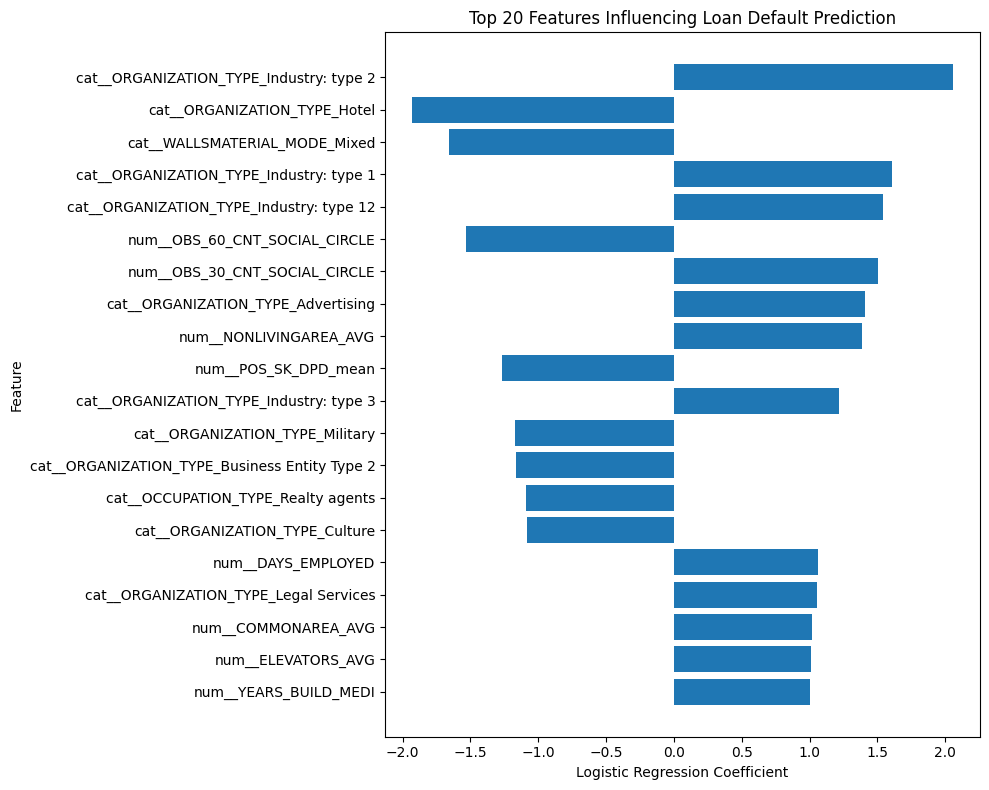

In [65]:
import matplotlib.pyplot as plt

# Recreate feature importance
feature_names = preprocessor.get_feature_names_out()
coefficients = trained_models["Logistic Regression"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

top20 = feature_importance.nlargest(20, "Absolute_Importance")
top20 = top20.sort_values("Absolute_Importance")

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Coefficient"])
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Loan Default Prediction")
plt.tight_layout()
plt.show()

In [66]:
import joblib
import os

# Save trained Logistic Regression model
joblib.dump(
    trained_models["Logistic Regression"],
    "/content/home_loan_default_model_combined.pkl"
)

# Save preprocessing object
joblib.dump(
    preprocessor,
    "/content/home_loan_preprocessor.pkl"
)

# Save original input feature columns
joblib.dump(
    X.columns.tolist(),
    "/content/home_loan_feature_columns.pkl"
)

print("Model saved successfully!")
print("Preprocessor saved successfully!")
print("Feature columns saved successfully!")

print("\nSaved files:")
print(os.listdir("/content"))

Model saved successfully!
Preprocessor saved successfully!
Feature columns saved successfully!

Saved files:
['.config', '.ipynb_checkpoints', 'bureau.csv', 'home_loan_default_model.pkl', 'application_train.csv', 'model_features.pkl', 'dataset', 'home_loan_preprocessor.pkl', 'home_loan_default_model_combined.pkl', 'previous_application.csv', 'installments_payments.csv', 'credit_card_balance.csv', 'POS_CASH_balance.csv', 'home_loan_feature_columns.pkl', 'bureau_balance.csv', 'drive', 'sample_data']


In [67]:
import joblib

# Load saved files
loaded_model = joblib.load(
    "/content/home_loan_default_model_combined.pkl"
)

loaded_preprocessor = joblib.load(
    "/content/home_loan_preprocessor.pkl"
)

loaded_features = joblib.load(
    "/content/home_loan_feature_columns.pkl"
)

# Select one customer from test data
sample_customer = X_test.iloc[[0]][loaded_features]

# Transform customer data
sample_processed = loaded_preprocessor.transform(sample_customer)

# Predict
prediction = loaded_model.predict(sample_processed)[0]
probability = loaded_model.predict_proba(sample_processed)[0][1]

print("Loan Default Prediction")
print("-----------------------")
print("Prediction:", "Defaulter" if prediction == 1 else "Non-Defaulter")
print("Default Probability:", round(probability * 100, 2), "%")

Loan Default Prediction
-----------------------
Prediction: Defaulter
Default Probability: 64.24 %


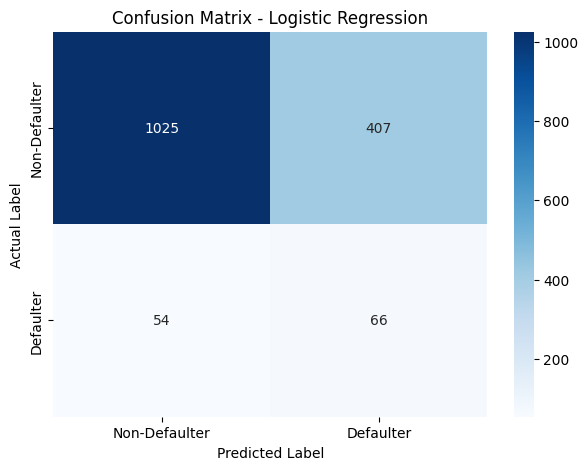

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = predictions["Logistic Regression"]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Defaulter", "Defaulter"],
    yticklabels=["Non-Defaulter", "Defaulter"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

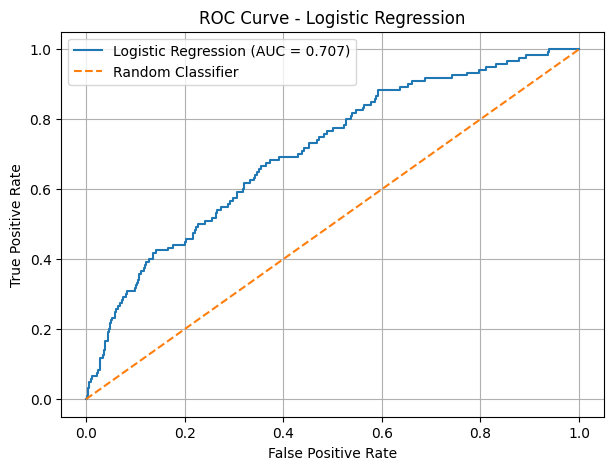

ROC-AUC Score: 0.7072


In [69]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities
y_probability = trained_models[
    "Logistic Regression"
].predict_proba(X_test_processed)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
roc_auc = roc_auc_score(y_test, y_probability)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

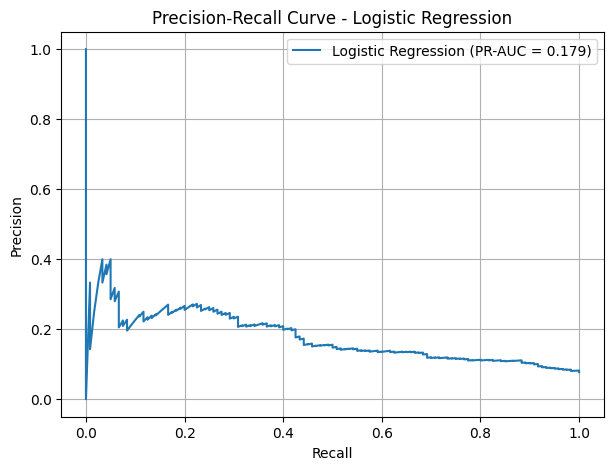

PR-AUC Score: 0.1788


In [70]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Predicted probabilities
y_probability = trained_models[
    "Logistic Regression"
].predict_proba(X_test_processed)[:, 1]

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(
    y_test, y_probability
)

pr_auc = average_precision_score(y_test, y_probability)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (PR-AUC = {pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("PR-AUC Score:", round(pr_auc, 4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7030,0.1395,0.5500,0.2226,0.7072,0.1788
1,Random Forest,0.8731,0.1765,0.1750,0.1757,0.6619,0.1613
2,Gradient Boosting,0.9188,0.3333,0.0500,0.0870,0.7374,0.1968
3,Random Forest + SMOTE,0.9104,0.2286,0.0667,0.1032,0.6835,0.1514


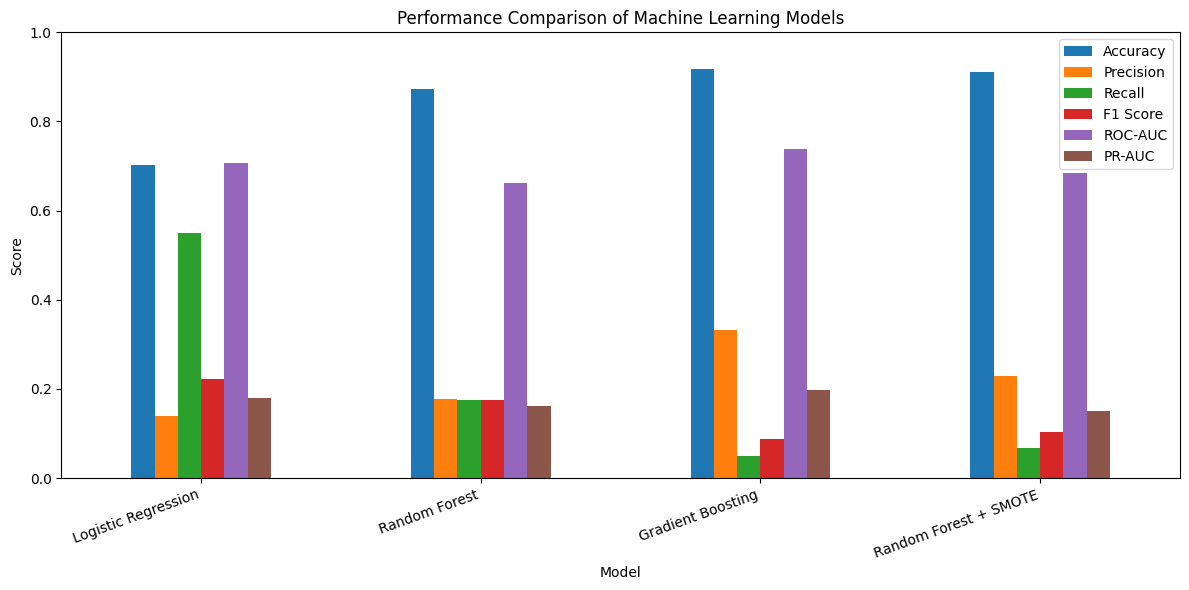

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "Random Forest + SMOTE"
    ],
    "Accuracy": [0.7030, 0.8731, 0.9188, 0.9104],
    "Precision": [0.1395, 0.1765, 0.3333, 0.2286],
    "Recall": [0.5500, 0.1750, 0.0500, 0.0667],
    "F1 Score": [0.2226, 0.1757, 0.0870, 0.1032],
    "ROC-AUC": [0.7072, 0.6619, 0.7374, 0.6835],
    "PR-AUC": [0.1788, 0.1613, 0.1968, 0.1514]
})

display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [72]:
# Save final merged dataset
df_final.to_csv(
    "/content/home_loan_final_dataset.csv",
    index=False
)

# Save model comparison table
comparison.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print("Final dataset saved!")
print("Model comparison saved!")

print("\nFile sizes:")
import os

for file in [
    "home_loan_final_dataset.csv",
    "model_comparison.csv"
]:
    path = "/content/" + file
    print(file, ":", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Final dataset saved!
Model comparison saved!

File sizes:
home_loan_final_dataset.csv : 6.79 MB
model_comparison.csv : 0.0 MB


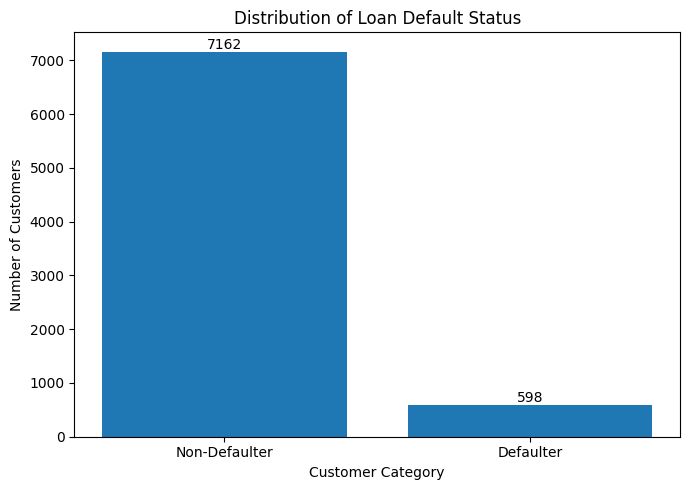

Target Distribution:
TARGET
0    7162
1     598
Name: count, dtype: int64

Percentage Distribution:
TARGET
0    92.29
1     7.71
Name: count, dtype: float64


In [73]:
import matplotlib.pyplot as plt

target_counts = df_final["TARGET"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Non-Defaulter", "Defaulter"],
    target_counts.values
)

plt.title("Distribution of Loan Default Status")
plt.xlabel("Customer Category")
plt.ylabel("Number of Customers")

for i, value in enumerate(target_counts.values):
    plt.text(i, value + 50, str(value), ha="center")

plt.tight_layout()
plt.show()

print("Target Distribution:")
print(target_counts)

print("\nPercentage Distribution:")
print((target_counts / len(df_final) * 100).round(2))

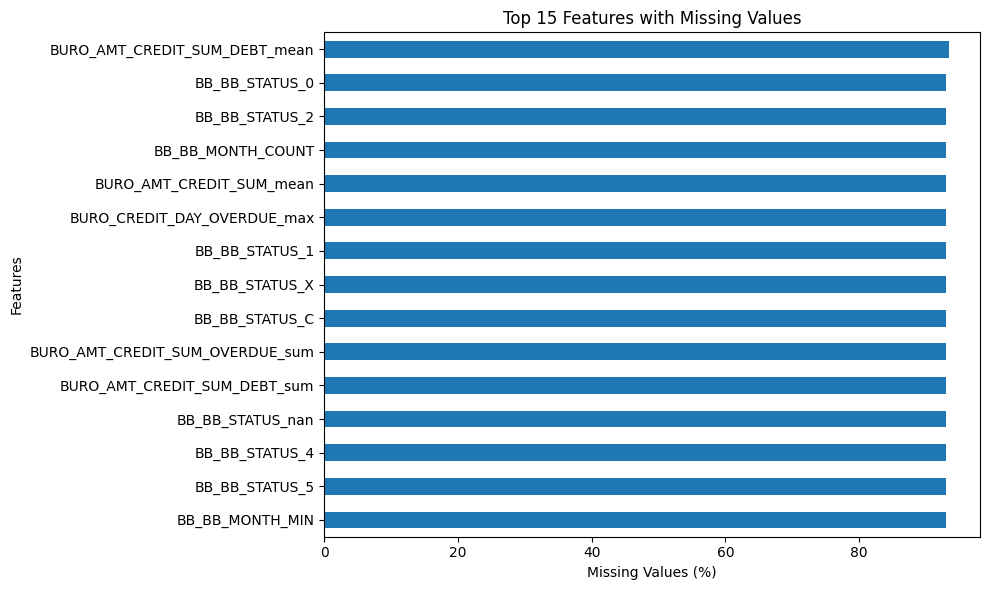

Total missing values: 659966
Total dataset columns: 224
Columns with missing values: 206


In [74]:
import pandas as pd
import matplotlib.pyplot as plt

missing_percentage = (
    df_final.isnull().mean() * 100
).sort_values(ascending=False)

top_missing = missing_percentage[missing_percentage > 0].head(15)

plt.figure(figsize=(10, 6))

top_missing.sort_values().plot(kind="barh")

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

print("Total missing values:", df_final.isnull().sum().sum())
print("Total dataset columns:", df_final.shape[1])
print("Columns with missing values:", (df_final.isnull().sum() > 0).sum())

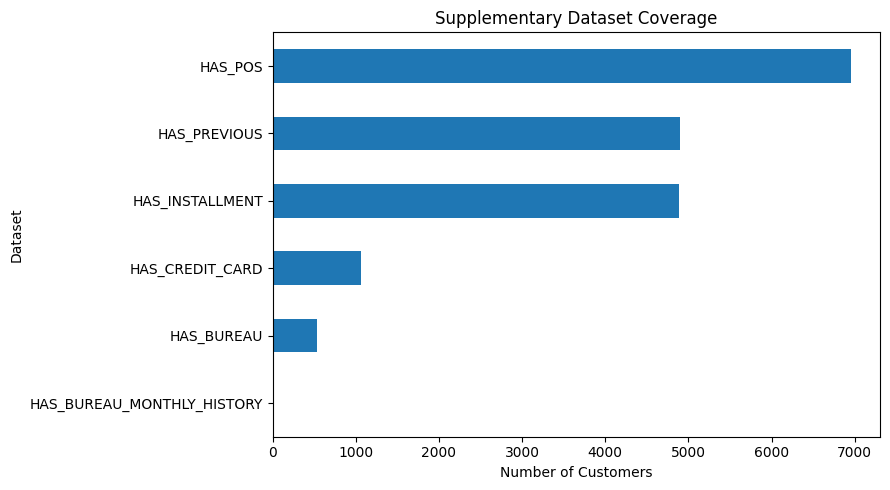

Customer Coverage:
HAS_BUREAU_MONTHLY_HISTORY      18
HAS_BUREAU                     539
HAS_CREDIT_CARD               1062
HAS_INSTALLMENT               4890
HAS_PREVIOUS                  4897
HAS_POS                       6956
dtype: int64


In [75]:
import matplotlib.pyplot as plt

coverage_columns = [
    "HAS_BUREAU",
    "HAS_BUREAU_MONTHLY_HISTORY",
    "HAS_POS",
    "HAS_PREVIOUS",
    "HAS_INSTALLMENT",
    "HAS_CREDIT_CARD"
]

coverage = df_final[coverage_columns].sum().sort_values()

plt.figure(figsize=(9, 5))

coverage.plot(kind="barh")

plt.title("Supplementary Dataset Coverage")
plt.xlabel("Number of Customers")
plt.ylabel("Dataset")

plt.tight_layout()
plt.show()

print("Customer Coverage:")
print(coverage)

## Data Challenges and Solutions

### 1. Missing Values
**Challenge:** Several columns contained missing values, particularly in supplementary financial datasets.

**Solution:** Median imputation was applied to numerical features, and most-frequent imputation was applied to categorical features using a preprocessing pipeline.

### 2. Class Imbalance
**Challenge:** Only 7.71% of customers were defaulters, while 92.29% were non-defaulters.

**Solution:** Class weighting and SMOTE were tested to address the imbalance.

### 3. Multiple Dataset Integration
**Challenge:** The project contained seven datasets with different numbers of records and structures.

**Solution:** Supplementary datasets were aggregated by customer ID (`SK_ID_CURR`) and merged with the main application dataset.

### 4. Incomplete Supplementary Information
**Challenge:** Not every customer had matching records in all supplementary datasets. Only 18 customers in the application sample had matching monthly bureau history.

**Solution:** Dataset coverage indicators were created to identify the availability of supplementary customer information.

### 5. Model Performance Trade-offs
**Challenge:** Models showed different performance across accuracy, precision, recall and F1-score.

**Solution:** Four machine learning approaches were compared. Logistic Regression achieved the highest defaulter recall (55%), while Gradient Boosting achieved the highest accuracy (91.88%).

### 6. Data Leakage Prevention
**Challenge:** Preprocessing before splitting data can cause information leakage.

**Solution:** The preprocessing pipeline was fitted only on training data and then applied to test data.

### 7. Limited Dataset Size
**Challenge:** The available application dataset contained 7,760 customer records, which is a partial sample.

**Solution:** The analysis and model evaluation were restricted to the available data, and the results were documented with this limitation.


## Data Challenges and Solutions

### 1. Missing Values
**Challenge:** Several columns contained missing values, particularly in supplementary financial datasets.

**Solution:** Median imputation was applied to numerical features, and most-frequent imputation was applied to categorical features using a preprocessing pipeline.

### 2. Class Imbalance
**Challenge:** Only 7.71% of customers were defaulters, while 92.29% were non-defaulters.

**Solution:** Class weighting and SMOTE were tested to address the imbalance.

### 3. Multiple Dataset Integration
**Challenge:** The project contained seven datasets with different numbers of records and structures.

**Solution:** Supplementary datasets were aggregated by customer ID (`SK_ID_CURR`) and merged with the main application dataset.

### 4. Incomplete Supplementary Information
**Challenge:** Not every customer had matching records in all supplementary datasets. Only 18 customers in the application sample had matching monthly bureau history.

**Solution:** Dataset coverage indicators were created to identify the availability of supplementary customer information.

### 5. Model Performance Trade-offs
**Challenge:** Models showed different performance across accuracy, precision, recall and F1-score.

**Solution:** Four machine learning approaches were compared. Logistic Regression achieved the highest defaulter recall (55%), while Gradient Boosting achieved the highest accuracy (91.88%).

### 6. Data Leakage Prevention
**Challenge:** Preprocessing before splitting data can cause information leakage.

**Solution:** The preprocessing pipeline was fitted only on training data and then applied to test data.

### 7. Limited Dataset Size
**Challenge:** The available application dataset contained 7,760 customer records, which is a partial sample.

**Solution:** The analysis and model evaluation were restricted to the available data, and the results were documented with this limitation.
